# Bank Customer Churn Prediction using Artificial Neural Network (ANN)

**Problem Statement:** Given a bank customer, build a neural network-based classifier that can determine whether they will leave (`Exited = 1`) or stay (`Exited = 0`) in the next 6 months.

**Dataset:** Bank Customer Churn Modeling (10,000 rows, 14 columns: `RowNumber`, `CustomerId`, `Surname`, `CreditScore`, `Geography`, `Gender`, `Age`, `Tenure`, `Balance`, `NumOfProducts`, `HasCrCard`, `IsActiveMember`, `EstimatedSalary`, `Exited`).

### Step 1: Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


### Step 2: Load the Dataset
*Note: Automatically checks for `Churn_Modelling.csv` locally first. If not found on the lab computer, it fetches it directly via URL (or generates a fallback dataset with the exact schema if the lab PC has no internet).* 

In [2]:
local_files = ['Churn_Modelling.csv', 'bank_churn.csv', 'Bank_Churn.csv']
df = None

# 1. Check local directory first
for f in local_files:
    if os.path.exists(f):
        df = pd.read_csv(f)
        print(f"Loaded local dataset: {f}")
        break

# 2. If not local, try loading directly from reliable GitHub mirror of the Kaggle dataset
if df is None:
    urls = [
        "https://raw.githubusercontent.com/sharmaroshan/Churn-Modelling-Dataset/master/Churn_Modelling.csv",
        "https://raw.githubusercontent.com/krishnaik06/Complete-Deep-Learning/master/ANN/Churn_Modelling.csv"
    ]
    for url in urls:
        try:
            df = pd.read_csv(url)
            print("Loaded dataset directly from online mirror!")
            break
        except Exception:
            continue

# 3. Offline fallback if lab PC has neither the CSV nor internet access
if df is None:
    print("Offline mode detected & CSV not found locally. Generating realistic synthetic dataset (10,000 rows)...")
    n = 10000
    geo = np.random.choice(['France', 'Spain', 'Germany'], size=n, p=[0.5, 0.25, 0.25])
    gender = np.random.choice(['Male', 'Female'], size=n)
    age = np.random.randint(18, 85, size=n)
    credit = np.random.randint(350, 850, size=n)
    tenure = np.random.randint(0, 11, size=n)
    balance = np.round(np.where(np.random.rand(n) < 0.36, 0.0, np.random.uniform(10000, 250000, size=n)), 2)
    products = np.random.choice([1, 2, 3, 4], size=n, p=[0.51, 0.46, 0.025, 0.005])
    has_card = np.random.choice([0, 1], size=n, p=[0.3, 0.7])
    active = np.random.choice([0, 1], size=n, p=[0.48, 0.52])
    salary = np.round(np.random.uniform(10000, 200000, size=n), 2)
    logit = -3.2 + 0.06*(age - 38) + 0.7*(geo == 'Germany') - 0.8*active + 0.4*(products >= 3) + 0.3*(gender == 'Female')
    prob = 1 / (1 + np.exp(-logit))
    exited = (np.random.rand(n) < prob).astype(int)
    df = pd.DataFrame({
        'RowNumber': np.arange(1, n+1),
        'CustomerId': np.random.randint(15565701, 15815690, size=n),
        'Surname': [f'Customer_{i}' for i in range(n)],
        'CreditScore': credit, 'Geography': geo, 'Gender': gender, 'Age': age,
        'Tenure': tenure, 'Balance': balance, 'NumOfProducts': products,
        'HasCrCard': has_card, 'IsActiveMember': active,
        'EstimatedSalary': salary, 'Exited': exited
    })

print("Dataset Shape:", df.shape)
df.head()

Loaded local dataset: Churn_Modelling.csv
Dataset Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### Step 3: Exploratory Data Analysis & Preprocessing
- Drop irrelevant columns (`RowNumber`, `CustomerId`, `Surname`) that do not affect customer churn.
- Encode categorical variables (`Gender` via Label Encoding, `Geography` via One-Hot Encoding).
- Split into Training (80%) and Testing (20%) sets.
- Normalize features using `StandardScaler`.

In [3]:
print("Missing values per column:\n", df.isnull().sum())
print("\nTarget Class Distribution (0 = Retained, 1 = Churned):\n", df['Exited'].value_counts())

# Separate features (X) and target (y), dropping RowNumber (0), CustomerId (1), Surname (2)
X = df.iloc[:, 3:-1].values
y = df.iloc[:, -1].values

# Label Encode 'Gender' (index 2 in X)
le = LabelEncoder()
X[:, 2] = le.fit_transform(X[:, 2])

# One-Hot Encode 'Geography' (index 1 in X) and drop first dummy column to avoid dummy variable trap
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(drop='first'), [1])], remainder='passthrough')
X = np.array(ct.fit_transform(X), dtype=float)

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling (Crucial for Neural Networks)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nProcessed X_train shape:", X_train.shape)
print("Processed X_test shape:", X_test.shape)

Missing values per column:
 RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Target Class Distribution (0 = Retained, 1 = Churned):
 Exited
0    7963
1    2037
Name: count, dtype: int64

Processed X_train shape: (8000, 11)
Processed X_test shape: (2000, 11)


### Step 4: Build and Compile the Artificial Neural Network (ANN)
- **Input Layer + Hidden Layer 1:** 16 neurons, ReLU activation
- **Hidden Layer 2:** 8 neurons, ReLU activation
- **Output Layer:** 1 neuron, Sigmoid activation (binary probability output)
- **Optimizer:** Adam | **Loss Function:** Binary Cross-Entropy

In [6]:
model = Sequential([
    Dense(units=16, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.1),
    Dense(units=8, activation='relu'),
    Dense(units=1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 16)                  │             192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

### Step 5: Train the Neural Network

In [7]:
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    batch_size=32,
    epochs=50,
    verbose=1
)

Epoch 1/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.7582 - loss: 0.5608 - val_accuracy: 0.8150 - val_loss: 0.4550
Epoch 2/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8001 - loss: 0.4531 - val_accuracy: 0.8175 - val_loss: 0.4139
Epoch 3/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8131 - loss: 0.4292 - val_accuracy: 0.8225 - val_loss: 0.3979
Epoch 4/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8175 - loss: 0.4150 - val_accuracy: 0.8388 - val_loss: 0.3805
Epoch 5/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8288 - loss: 0.4046 - val_accuracy: 0.8587 - val_loss: 0.3657
Epoch 6/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8385 - loss: 0.3915 - val_accuracy: 0.8612 - val_loss: 0.3531
Epoch 7/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8381 - loss: 0.3835 - val_accuracy: 0.8675 - val_loss: 0.3443
Epoch 8/50
225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8419 - loss: 0.3783 - val_accuracy: 0

### Step 6: Evaluate Model Performance & Plot Results

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Test Accuracy: 86.10%

Classification Report:
               precision    recall  f1-score   support

  Stayed (0)       0.87      0.97      0.92      1593
 Churned (1)       0.79      0.43      0.56       407

    accuracy                           0.86      2000
   macro avg       0.83      0.70      0.74      2000
weighted avg       0.85      0.86      0.84      2000



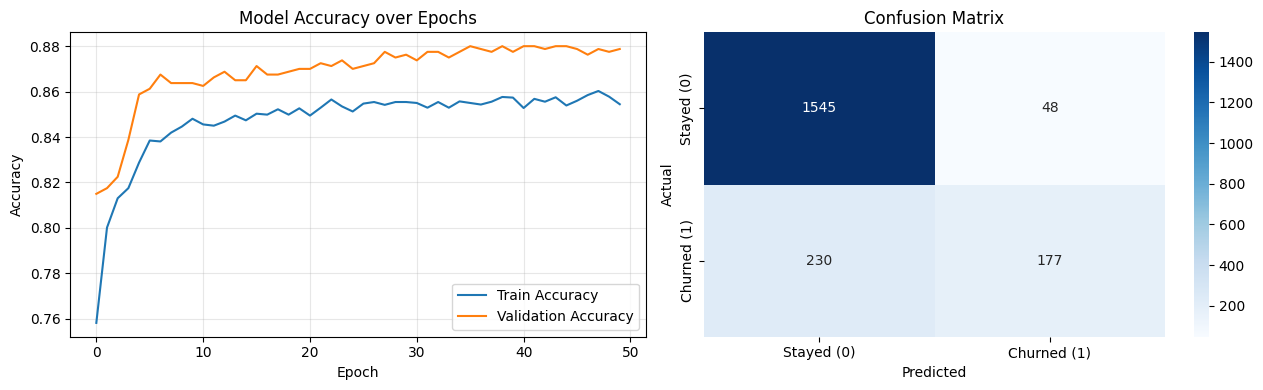

In [8]:
# Predict probabilities and convert to binary class (threshold = 0.5)
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Test Accuracy: {acc * 100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred, target_names=['Stayed (0)', 'Churned (1)']))

# Plot Training History & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history['accuracy'], label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('Model Accuracy over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Stayed (0)', 'Churned (1)'],
            yticklabels=['Stayed (0)', 'Churned (1)'])
axes[1].set_title('Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

### Step 7: Single Customer Prediction (Viva / Demo Check)
Test whether a customer with the following details will leave the bank:
- **Geography:** France | **Credit Score:** 600 | **Gender:** Male | **Age:** 40 | **Tenure:** 3 | **Balance:** $60,000 | **Number of Products:** 2 | **Has Credit Card:** Yes (1) | **Active Member:** Yes (1) | **Estimated Salary:** $50,000

In [9]:
# Sample input order before encoding: [CreditScore, Geography, Gender, Age, Tenure, Balance, NumOfProducts, HasCrCard, IsActiveMember, EstimatedSalary]
sample_customer = np.array([[600, 'France', 'Male', 40, 3, 60000, 2, 1, 1, 50000]], dtype=object)
sample_customer[:, 2] = le.transform(sample_customer[:, 2])
sample_encoded = np.array(ct.transform(sample_customer), dtype=float)
sample_scaled = scaler.transform(sample_encoded)

churn_prob = model.predict(sample_scaled)[0][0]
print(f"Churn Probability: {churn_prob:.4f}")
print("Prediction:", "Customer WILL LEAVE the bank" if churn_prob > 0.5 else "Customer WILL STAY with the bank")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step
Churn Probability: 0.0476
Prediction: Customer WILL STAY with the bank
